In [ ]:
import os
import sys
import io
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw, ImageFont
from dotenv import load_dotenv

project_root = os.path.abspath('..')
if project_root not in sys.path:
    sys.path.append(project_root)

load_dotenv(os.path.join(project_root, '.env'))

try:
    from src.services.ocr import analyze_image
    from src.services.allergen import analyze_ingredients
    print("✅ Core services imported successfully.")
except ImportError as e:
    print(f"❌ Error importing services: {e}")
    print("Please ensure you are running this notebook from the 'notebooks' directory and 'src' is accessible.")


✅ Core services imported successfully.


d:\free\2025_2026_secend_term\00_ALLERGENS_DETECTION\Ai\Allergen_Detector\src\services\ocr.py:1: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  import google.generativeai as genai


## 2. Synthetic Data Generation
Since we don't have a labeled dataset handy, we will generate synthetic images containing ingredient text. This allows us to control the "Ground Truth" for accuracy testing.

In [ ]:
def create_dummy_image(text, filename="temp_test.png"):
    """Creates a simple image with text for OCR testing."""
    img = Image.new('RGB', (800, 200), color=(255, 255, 255))
    d = ImageDraw.Draw(img)
    try:
        font = ImageFont.truetype("arial.ttf", 20)
    except IOError:
        font = ImageFont.load_default()
    
    d.text((10, 10), text, fill=(0, 0, 0), font=font)
    
    img_byte_arr = io.BytesIO()
    img.save(img_byte_arr, format='PNG')
    return img_byte_arr.getvalue()

test_cases = [
    (
        "Ingredients: Water, Sugar, Peanuts, Salt.", 
        ["Peanut"], 
        False, 
        ["Peanut"]
    ),
    (
        "Ingredients: Whole Milk, Cocoa Butter, Wheat Flour.", 
        ["Milk", "Wheat"], 
        False, 
        ["Milk", "Wheat"]
    ),
    (
        "Ingredients: Apples, Water, Ascorbic Acid.", 
        ["Peanut", "Shellfish"], 
        True, 
        []
    ),
    (
        "Ingredients: Soy Protein Isolate, Vegetable Oil, Natural Flavors.", 
        ["Soy"], 
        False, 
        ["Soy"]
    ),
    (
        "Ingredients: Almonds, Sea Salt.", 
        ["Peanut"], 
        True, 
        [] 
    )
]

print(f"Created {len(test_cases)} test cases.")

Created 5 test cases.


## 3. Run Analysis Models

In [ ]:
results = []

print("Running analysis... may take a moment for API calls.")

for idx, (text, user_allergens, expected_safe, expected_detected) in enumerate(test_cases):
    print(f"Processing Case {idx + 1}...")
    
    image_bytes = create_dummy_image(text)
    
   
    gemini_result = analyze_image(image_bytes, user_allergens)
    
    local_result = analyze_ingredients(text, user_allergens)
    
    gemini_safe = False
    if isinstance(gemini_result, dict):
        gemini_status = gemini_result.get('status', 'Unknown')
        gemini_safe = (gemini_status == 'Safe')
        gemini_text_extracted = gemini_result.get('raw_text', '')
        gemini_detected = [d['word'] for d in gemini_result.get('detected_allergens', [])]
    else:
        gemini_safe = None
        gemini_detected = []
        
    local_safe = local_result.get('is_safe', False)
    local_detected = [f['matched_term'] for f in local_result.get('found_allergens', [])]
    
    results.append({
        'Case': idx + 1,
        'Input_Text': text,
        'User_Allergens': user_allergens,
        'Ground_Truth_Safe': expected_safe,
        'Gemini_Safe': gemini_safe,
        'Local_Safe': local_safe,
        'Gemini_Detected': gemini_detected,
        'Local_Detected': local_detected
    })

df = pd.DataFrame(results)
print("Analysis Complete.")
display(df)

Running analysis... may take a moment for API calls.
Processing Case 1...
Processing Case 2...
Processing Case 3...
Processing Case 4...
Processing Case 5...
Analysis Complete.


,Case,Input_Text,User_Allergens,Ground_Truth_Safe,Gemini_Safe,Local_Safe,Gemini_Detected,Local_Detected
0,1,"Ingredients: Water, Sugar, Peanuts, Salt.",[Peanut],False,False,False,[Peanuts],[peanut]
1,2,"Ingredients: Whole Milk, Cocoa Butter, Wheat F...","[Milk, Wheat]",False,False,False,"[Whole Milk, Wheat Flour]","[milk, wheat]"
2,3,"Ingredients: Apples, Water, Ascorbic Acid.","[Peanut, Shellfish]",True,True,True,[],[]
3,4,"Ingredients: Soy Protein Isolate, Vegetable Oi...",[Soy],False,False,False,[Soy Protein Isolate],[soy]
4,5,"Ingredients: Almonds, Sea Salt.",[Peanut],True,True,True,[],[]


## 4. Visualization & Accuracy Metrics

Gemini Model Accuracy: 100.00%
Local Fuzzy Model Accuracy: 100.00%


C:\Users\Mahmoud.Salama\AppData\Local\Temp\ipykernel_34848\2475001916.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Gemini Model', 'Local Model'], y=[gemini_accuracy, local_accuracy], palette='viridis')


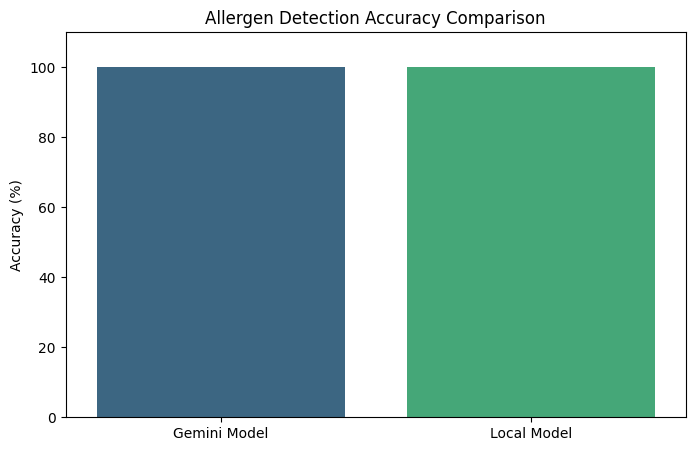

In [ ]:
df['Gemini_Correct'] = df['Gemini_Safe'] == df['Ground_Truth_Safe']
df['Local_Correct'] = df['Local_Safe'] == df['Ground_Truth_Safe']

gemini_accuracy = df['Gemini_Correct'].mean() * 100
local_accuracy = df['Local_Correct'].mean() * 100

print(f"Gemini Model Accuracy: {gemini_accuracy:.2f}%")
print(f"Local Fuzzy Model Accuracy: {local_accuracy:.2f}%")

plt.figure(figsize=(8, 5))
sns.barplot(x=['Gemini Model', 'Local Model'], y=[gemini_accuracy, local_accuracy], palette='viridis')
plt.ylim(0, 110)
plt.ylabel('Accuracy (%)')
plt.title('Allergen Detection Accuracy Comparison')
plt.show()

## 5. Detailed Error Analysis
Let's look at where the models might have failed.

In [7]:
failed_cases = df[~(df['Gemini_Correct'] & df['Local_Correct'])]

if not failed_cases.empty:
    print("Discrepancies found:")
    display(failed_cases[['Case', 'Input_Text', 'Ground_Truth_Safe', 'Gemini_Safe', 'Local_Safe']])
else:
    print("✅ Both models performed perfectly on this synthetic dataset!")

✅ Both models performed perfectly on this synthetic dataset!


In [13]:
from src.utils.image_processing import get_preprocessing_stages
from src.services.ocr import  *
with open("test_image.jpg", "rb") as image_file:
    image_bytes = image_file.read()
result=analyze_image(image_bytes, ["Peanut", "Milk"])
print(result)


{'status': 'Not Safe', 'color': 'red', 'detected_allergens': [{'word': 'Milk', 'category': 'Milk', 'risk': 'High'}, {'word': 'Cheese', 'category': 'Milk', 'risk': 'High'}, {'word': 'Yogurt', 'category': 'Milk', 'risk': 'High'}, {'word': 'Ice Cream', 'category': 'Milk', 'risk': 'High'}, {'word': 'Butter', 'category': 'Milk', 'risk': 'High'}, {'word': 'Sour Cream', 'category': 'Milk', 'risk': 'High'}, {'word': 'Peanuts', 'category': 'Peanut', 'risk': 'High'}, {'word': 'Peanut Butter', 'category': 'Peanut', 'risk': 'High'}, {'word': 'Chocolate', 'category': 'Peanut', 'risk': 'High'}, {'word': 'Baked Goods', 'category': 'Peanut', 'risk': 'High'}, {'word': 'Protein Bars', 'category': 'Peanut', 'risk': 'High'}], 'raw_text': 'Cheese, Yogurt, Ice Cream, Butter, Sour Cream, Mayonnaise, Hollandaise, Tartar Sauce, Baked Goods, Quiche, Peanuts, Peanut Butter, Chocolate, Baked Goods, Protein Bars, Pecans, Pistachios, Walnuts, Hazelnuts, Almonds, Cashews, Any Finned Fish, Shrimp, Crab, Lobster, Cere